In [10]:
import pandas as pd
import numpy as np

# Load modeling dataset
df = pd.read_csv('../data/processed/nigeria_modeling_dataset.csv')

# Geopolitical zone mapping
GEO_ZONES = {
    'North Central': ['Benue', 'Kogi', 'Kwara', 'Nasarawa', 'Niger', 'Plateau', 'Abuja', 'Federal Capital Territory'],
    'North East': ['Adamawa', 'Bauchi', 'Borno', 'Gombe', 'Taraba', 'Yobe'],
    'North West': ['Jigawa', 'Kaduna', 'Kano', 'Katsina', 'Kebbi', 'Sokoto', 'Zamfara'],
    'South East': ['Abia', 'Anambra', 'Ebonyi', 'Enugu', 'Imo'],
    'South South': ['Akwa Ibom', 'Bayelsa', 'Cross River', 'Delta', 'Edo', 'Rivers'],
    'South West': ['Ekiti', 'Lagos', 'Ogun', 'Ondo', 'Osun', 'Oyo']
}

zone_map = {state: zone for zone, states in GEO_ZONES.items() for state in states}
df['geo_zone'] = df['state_name'].map(zone_map)

# Encode geopolitical zones as integer IDs (0 to 5) for scikit-learn compatibility
df['geo_zone_id'] = pd.factorize(df['geo_zone'])[0]

# Feature matrix X, target y, and integer group IDs
df['log_viirs'] = np.log1p(df['viirs_mean_radiance'])
X = df[['log_viirs', 'modis_mean_ndvi']].values
y = df['poverty_rate_pct'].values
groups = df['geo_zone_id'].values

print(f"Dataset shape: {X.shape}")
print(f"Unique groups: {np.unique(groups)}")
print("\nDistribution across Geopolitical Zones:")
print(df['geo_zone'].value_counts())

Dataset shape: (37, 2)
Unique groups: [-1  0  1  2  3  4  5]

Distribution across Geopolitical Zones:
geo_zone
North West       7
South West       6
North Central    6
South South      6
North East       6
South East       5
Name: count, dtype: int64


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

ols = LinearRegression()
ols.fit(X, y)
y_pred = ols.predict(X)

print("--- OLS Full-Sample Fit ---")
print(f"R² Score       : {r2_score(y, y_pred):.3f}")
print(f"RMSE (% points): {np.sqrt(mean_squared_error(y, y_pred)):.2f}")
print(f"MAE (% points) : {mean_absolute_error(y, y_pred):.2f}")
print(f"Coefficients   : log(VIIRS) = {ols.coef_[0]:.2f}, NDVI = {ols.coef_[1]:.2f}")
print(f"Intercept      : {ols.intercept_:.2f}")

--- OLS Full-Sample Fit ---
R² Score       : 0.860
RMSE (% points): 9.07
MAE (% points) : 7.02
Coefficients   : log(VIIRS) = -43.93, NDVI = -193.96
Intercept      : 160.81


In [12]:
from sklearn.model_selection import KFold, LeaveOneGroupOut, cross_val_predict
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_squared_error

models = {
    'OLS Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=3, random_state=42)
}

results = []

# 1. Random 5-Fold Cross Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Spatial Group Cross Validation (Leave-One-Geopolitical-Zone-Out)
logo = LeaveOneGroupOut()

for name, model in models.items():
    # Random CV predictions
    y_pred_random = cross_val_predict(model, X, y, cv=kf)
    r2_random = r2_score(y, y_pred_random)
    rmse_random = np.sqrt(mean_squared_error(y, y_pred_random))
    
    # Spatial CV predictions (using integer groups)
    y_pred_spatial = cross_val_predict(model, X, y, cv=logo, groups=groups)
    r2_spatial = r2_score(y, y_pred_spatial)
    rmse_spatial = np.sqrt(mean_squared_error(y, y_pred_spatial))
    
    results.append({
        'Model': name,
        'Random CV R²': round(r2_random, 3),
        'Random CV RMSE': round(rmse_random, 2),
        'Spatial CV R²': round(r2_spatial, 3),
        'Spatial CV RMSE': round(rmse_spatial, 2),
    })

df_eval = pd.DataFrame(results)
print("=== Cross-Validation Evaluation ===")
print(df_eval.to_string(index=False))

=== Cross-Validation Evaluation ===
                Model  Random CV R²  Random CV RMSE  Spatial CV R²  Spatial CV RMSE
OLS Linear Regression         0.804           10.73          0.810            10.56
     Ridge Regression         0.463           17.76          0.315            20.06
        Random Forest         0.438           18.17          0.511            16.95


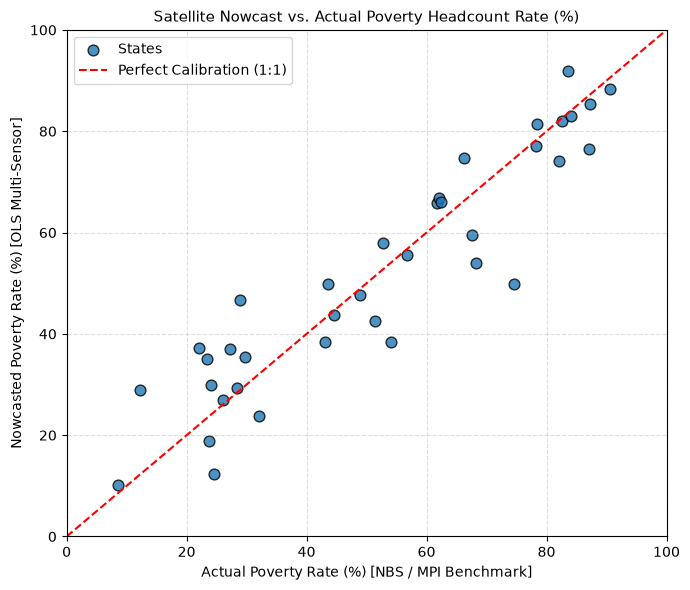

✓ Saved calibration plot to docs/baseline_calibration.png


In [13]:
import matplotlib.pyplot as plt

# Using the full-sample OLS predictions from Cell 2
plt.figure(figsize=(7, 6))
plt.scatter(y, y_pred, color='#1f77b4', edgecolors='k', s=60, alpha=0.8, label='States')
plt.plot([0, 100], [0, 100], 'r--', label='Perfect Calibration (1:1)')

plt.title("Satellite Nowcast vs. Actual Poverty Headcount Rate (%)", fontsize=11)
plt.xlabel("Actual Poverty Rate (%) [NBS / MPI Benchmark]")
plt.ylabel("Nowcasted Poverty Rate (%) [OLS Multi-Sensor]")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()

plt.tight_layout()
plt.savefig('../docs/baseline_calibration.png', dpi=300)
plt.show()

print("✓ Saved calibration plot to docs/baseline_calibration.png")